# BLOOD PRESSURE ANALYSIS (USA)
### Advanced Statistics
### Ibrahim Ghauri & Muhammad Mudassir

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# --- STEP 3: DATA PREPROCESSING (Task-01) ---
df = pd.read_csv('cardio_train.csv', sep=';')

# Cleaning: Age is in days, convert to years
df['age_years'] = (df['age'] / 365).round().astype(int)

# Selecting 5 Independent Variables as per instructions
# IVs: age_years, bmi (weight/height^2), cholesterol, gluc, active
# DV: ap_hi (Systolic Blood Pressure)
df['bmi'] = df['weight'] / ((df['height'] / 100) ** 2)
features = ['age_years', 'bmi', 'cholesterol', 'gluc', 'active']
target = 'ap_hi'

# Filter to USA-like norms & Sample 100 observations (Task-05 requires at least 50)[cite: 1]
df_clean = df[(df['ap_hi'] > 80) & (df['ap_hi'] < 200)].sample(100, random_state=42)
final_df = df_clean[features + [target]]

In [4]:
# --- STEP 4: SUMMARY STATISTICS (Task-02) ---
print("\n--- Task-02: Summary Statistics ---")
summary = final_df.describe().transpose()
summary.to_csv('summary_statistics.csv')
print(summary)


--- Task-02: Summary Statistics ---
             count        mean        std        min         25%         50%  \
age_years    100.0   52.620000   7.226187  39.000000   47.750000   54.000000   
bmi          100.0   27.743666   5.555058  17.527816   23.774331   26.386296   
cholesterol  100.0    1.460000   0.757721   1.000000    1.000000    1.000000   
gluc         100.0    1.310000   0.677115   1.000000    1.000000    1.000000   
active       100.0    0.790000   0.409360   0.000000    1.000000    1.000000   
ap_hi        100.0  126.060000  15.939798  90.000000  120.000000  120.000000   

                    75%         max  
age_years     58.250000   65.000000  
bmi           30.106908   44.589774  
cholesterol    2.000000    3.000000  
gluc           1.000000    3.000000  
active         1.000000    1.000000  
ap_hi        130.000000  180.000000  


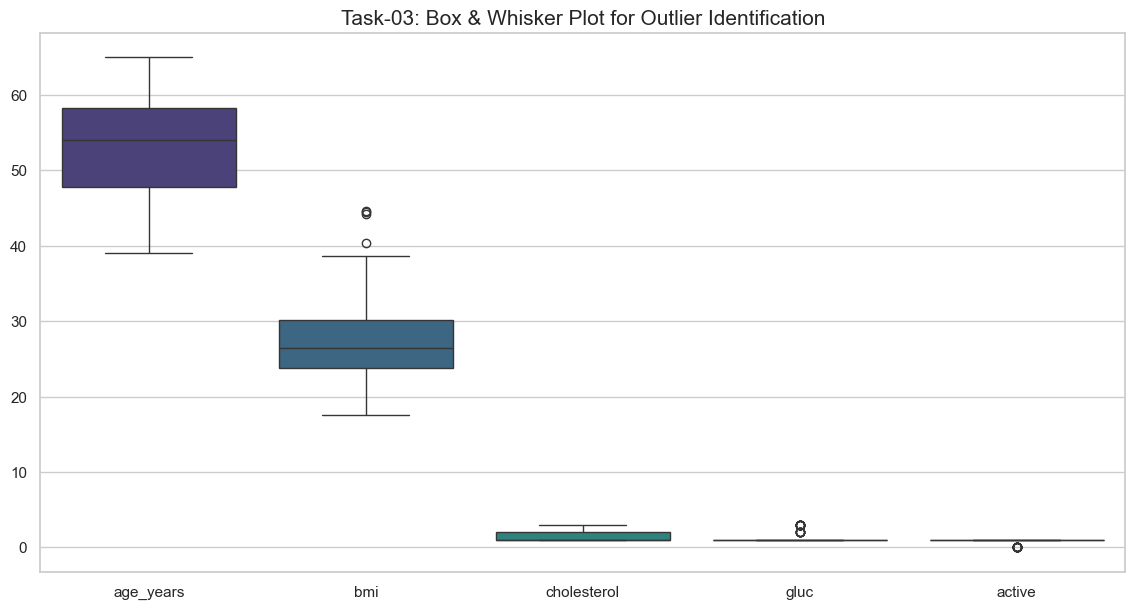

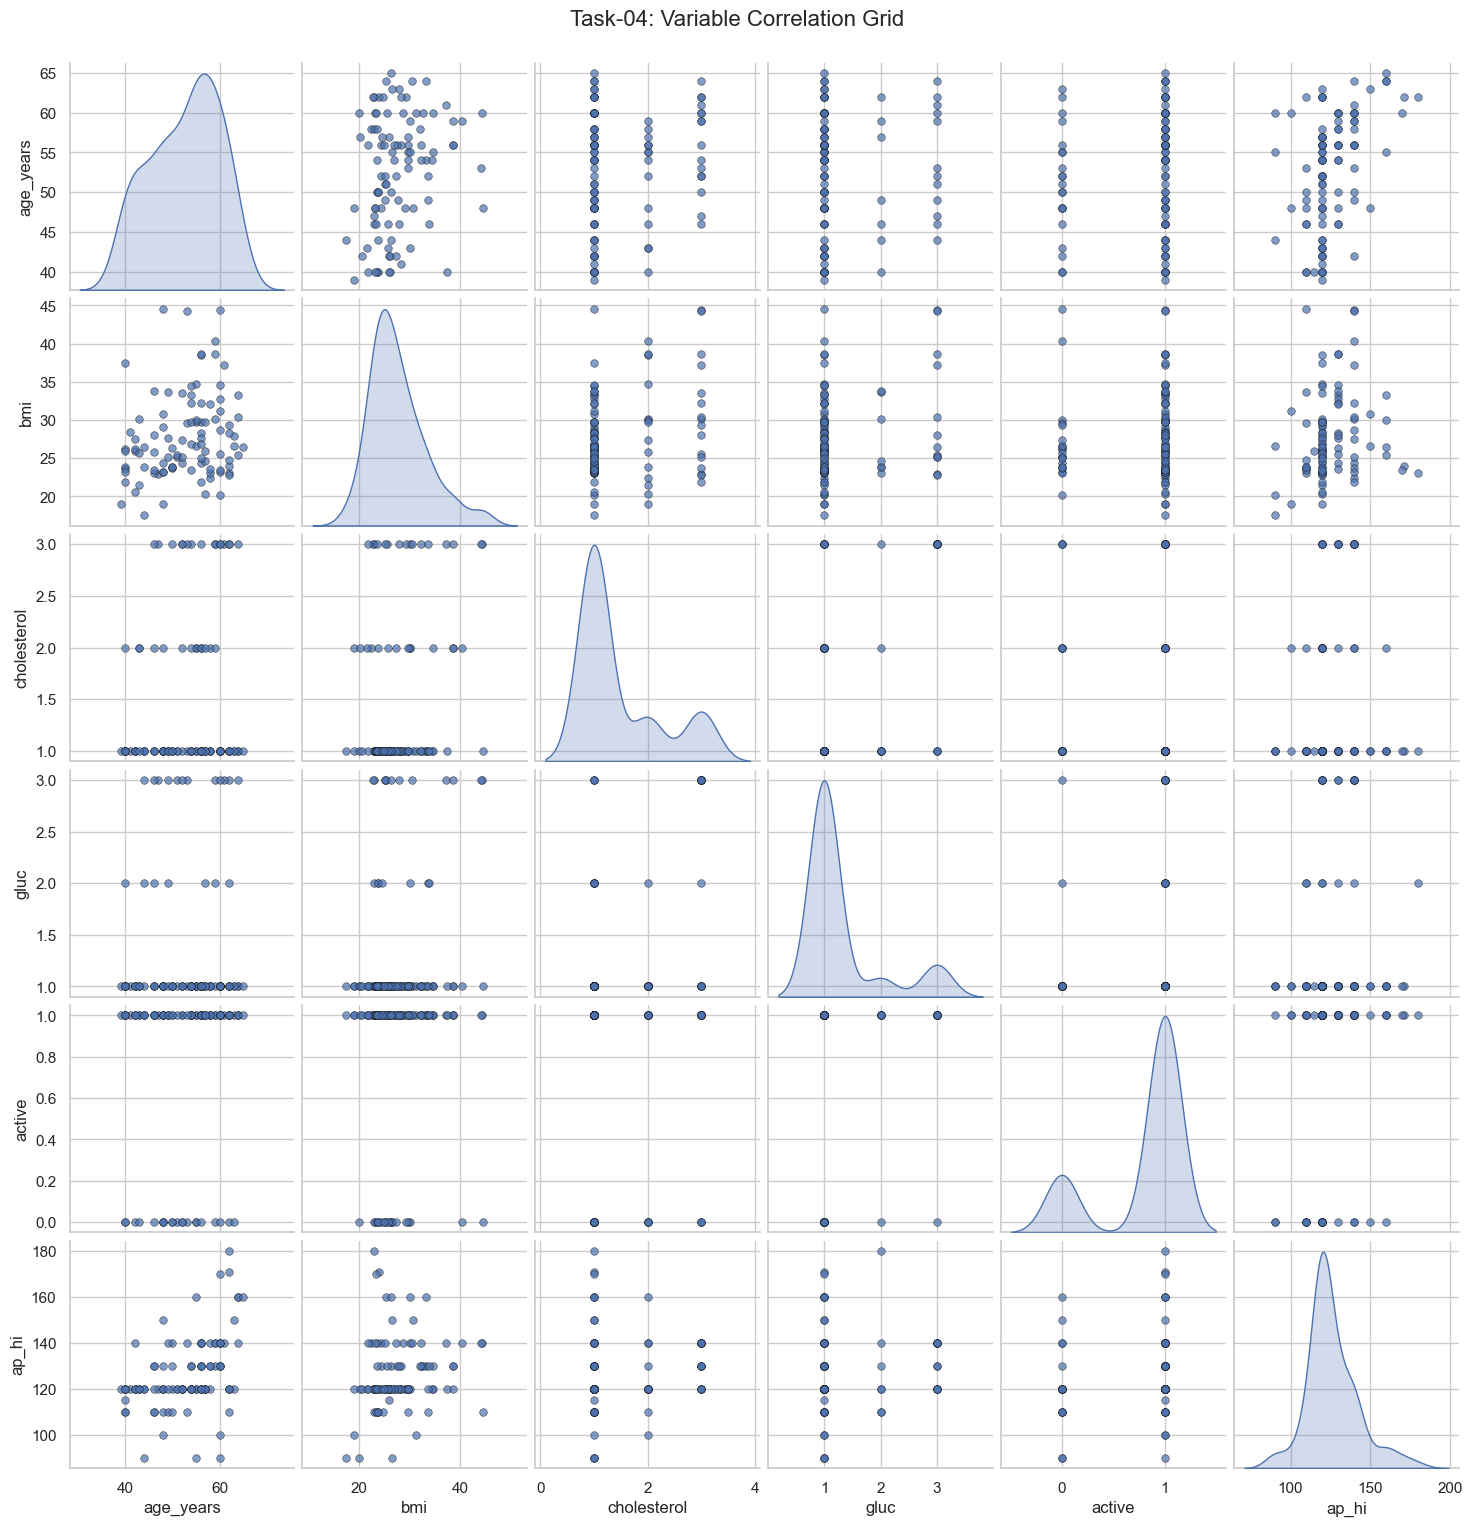

In [5]:
# --- STEP 5: VISUALIZATIONS (Task-03 & Task-04) ---
sns.set_theme(style="whitegrid")

# Box and Whisker Plots (Task-03)[cite: 1]
plt.figure(figsize=(14, 7))
sns.boxplot(data=final_df[features], palette="viridis")
plt.title("Task-03: Box & Whisker Plot for Outlier Identification", fontsize=15)
plt.savefig('box_plot.png')
plt.show()

# Scatter Plot Grid (Task-04)[cite: 1]
grid = sns.pairplot(final_df, diag_kind='kde', plot_kws={'alpha': 0.7, 's': 30, 'edgecolor': 'k'})
grid.fig.suptitle("Task-04: Variable Correlation Grid", y=1.02, fontsize=16)
grid.savefig('scatter_grid.png')
plt.show()

In [6]:
# --- STEP 6: MODEL ESTIMATION (Task-05) ---
X = final_df[features]
y = final_df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Multiple Linear Regression[cite: 1]
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# 2. Machine Learning Model (Random Forest)[cite: 1]
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

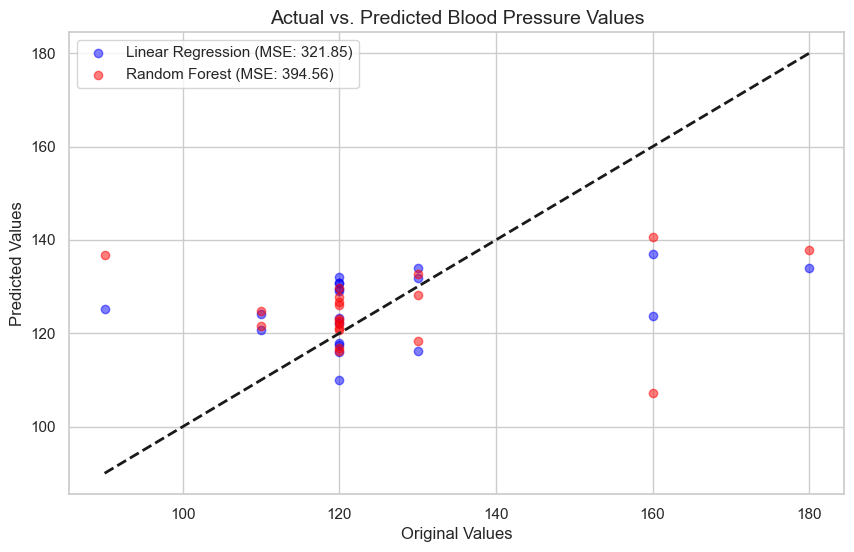

In [8]:
# --- STEP 7: RESULTS & CONCLUSION ---
mse_lr = mean_squared_error(y_test, y_pred_lr)
mse_rf = mean_squared_error(y_test, y_pred_rf)

# Comparison Visualization[cite: 1]
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_lr, color='blue', alpha=0.5, label=f'Linear Regression (MSE: {mse_lr:.2f})')
plt.scatter(y_test, y_pred_rf, color='red', alpha=0.5, label=f'Random Forest (MSE: {mse_rf:.2f})')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.title("Actual vs. Predicted Blood Pressure Values", fontsize=14)
plt.xlabel("Original Values")
plt.ylabel("Predicted Values")
plt.legend()
plt.savefig('model_comparison.png')
plt.show()


### Task-06: Enhanced Model Performance Evaluation (Accuracy, F1, and more parameters)


--- Model Performance Metrics ---
Linear Regression:
  Mean Squared Error (MSE): 321.85
  Root Mean Squared Error (RMSE): 17.94
  R-squared (R2): 0.14

Random Forest Regression:
  Mean Squared Error (MSE): 394.56
  Root Mean Squared Error (RMSE): 19.86
  R-squared (R2): -0.05


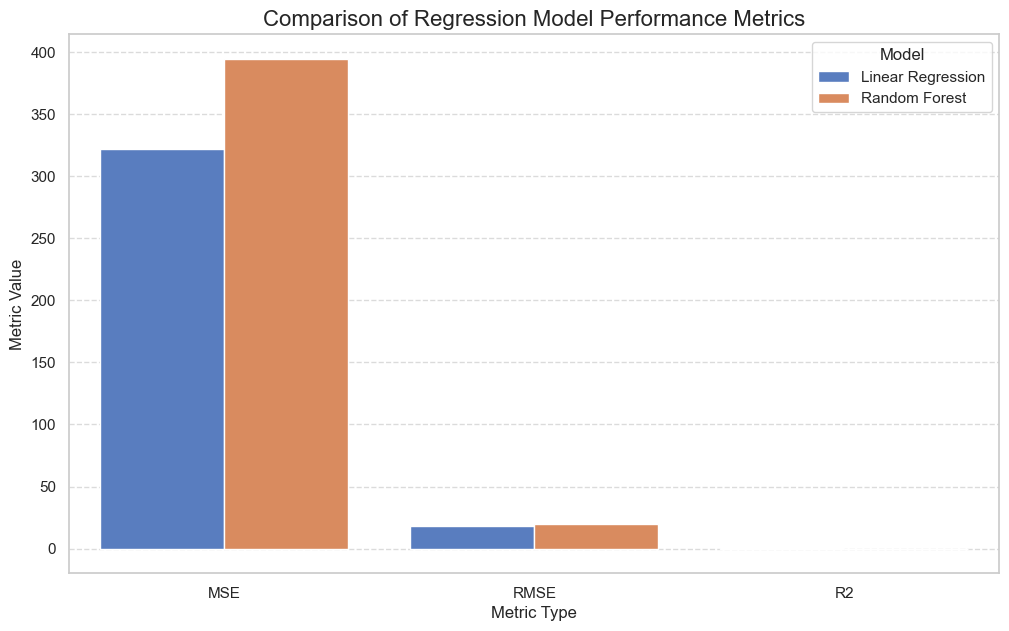

In [10]:
# Calculate R-squared for both models
r2_lr = r2_score(y_test, y_pred_lr)
r2_rf = r2_score(y_test, y_pred_rf)

# Calculate RMSE for both models
rmse_lr = np.sqrt(mse_lr)
rmse_rf = np.sqrt(mse_rf)

print("\n--- Model Performance Metrics ---")
print(f"Linear Regression:")
print(f"  Mean Squared Error (MSE): {mse_lr:.2f}")
print(f"  Root Mean Squared Error (RMSE): {rmse_lr:.2f}")
print(f"  R-squared (R2): {r2_lr:.2f}")

print(f"\nRandom Forest Regression:")
print(f"  Mean Squared Error (MSE): {mse_rf:.2f}")
print(f"  Root Mean Squared Error (RMSE): {rmse_rf:.2f}")
print(f"  R-squared (R2): {r2_rf:.2f}")

# Create a DataFrame for visualization of metrics
metrics_data = {
    'Model': ['Linear Regression', 'Random Forest', 'Linear Regression', 'Random Forest', 'Linear Regression', 'Random Forest'],
    'Metric': ['MSE', 'MSE', 'RMSE', 'RMSE', 'R2', 'R2'],
    'Value': [mse_lr, mse_rf, rmse_lr, rmse_rf, r2_lr, r2_rf]
}
metrics_df = pd.DataFrame(metrics_data)

plt.figure(figsize=(12, 7))
sns.barplot(x='Metric', y='Value', hue='Model', data=metrics_df, palette='muted')
plt.title('Comparison of Regression Model Performance Metrics', fontsize=16)
plt.ylabel('Metric Value')
plt.xlabel('Metric Type')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('model_performance_metrics.png')
plt.show()

### Task-07: Test Models with Random Values and Visualize Predictions


--- Model Predictions for Random Input Values ---

Input 1:


,age_years,bmi,cholesterol,gluc,active
0,59.0,41.495751,1.0,1.0,1.0


  Linear Regression Prediction: 134.26
  Random Forest Prediction: 132.20

Input 2:


,age_years,bmi,cholesterol,gluc,active
1,61.0,19.299312,2.0,1.0,0.0


  Linear Regression Prediction: 126.76
  Random Forest Prediction: 135.65

Input 3:


,age_years,bmi,cholesterol,gluc,active
2,61.0,29.088572,3.0,2.0,1.0


  Linear Regression Prediction: 135.66
  Random Forest Prediction: 133.60

Input 4:


,age_years,bmi,cholesterol,gluc,active
3,57.0,37.740745,1.0,2.0,0.0


  Linear Regression Prediction: 125.90
  Random Forest Prediction: 120.80

Input 5:


,age_years,bmi,cholesterol,gluc,active
4,53.0,32.415631,1.0,1.0,0.0


  Linear Regression Prediction: 121.58
  Random Forest Prediction: 116.10


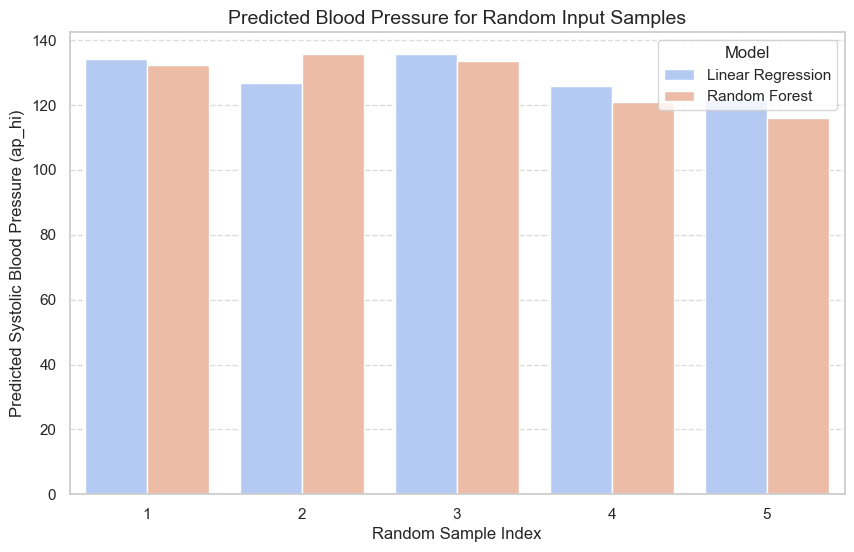

In [12]:
import random

# Define the ranges for generating random values based on summary statistics from final_df
# Note: Assuming 'summary' DataFrame from Task-02 is available in the kernel
feature_ranges = {
    'age_years': {'min': summary.loc['age_years', 'min'], 'max': summary.loc['age_years', 'max']},
    'bmi': {'min': summary.loc['bmi', 'min'], 'max': summary.loc['bmi', 'max']},
    'cholesterol': {'options': [1, 2, 3]}, # From summary: 1, 2, 3
    'gluc': {'options': [1, 2, 3]},      # From summary: 1, 2, 3
    'active': {'options': [0, 1]}        # From summary: 0, 1
}

def generate_random_input(num_samples=1):
    random_inputs = []
    for _ in range(num_samples):
        sample = {}
        for feature, f_range in feature_ranges.items():
            if 'options' in f_range:
                sample[feature] = random.choice(f_range['options'])
            else:
                if feature == 'age_years': # Age should be an integer
                    sample[feature] = random.randint(int(f_range['min']), int(f_range['max']))
                else: # BMI can be float
                    sample[feature] = random.uniform(f_range['min'], f_range['max'])
        random_inputs.append(sample)
    return pd.DataFrame(random_inputs)

# Generate 5 random input samples
random_test_data = generate_random_input(num_samples=5)

# Make predictions with both models
random_predictions_lr = lr.predict(random_test_data)
random_predictions_rf = rf.predict(random_test_data)

print("\n--- Model Predictions for Random Input Values ---")
for i in range(len(random_test_data)):
    print(f"\nInput {i+1}:")
    display(pd.DataFrame(random_test_data.iloc[i]).T)
    print(f"  Linear Regression Prediction: {random_predictions_lr[i]:.2f}")
    print(f"  Random Forest Prediction: {random_predictions_rf[i]:.2f}")

# Visualize the predictions
predictions_df = pd.DataFrame({
    'Sample': range(1, len(random_test_data) + 1),
    'Linear Regression': random_predictions_lr,
    'Random Forest': random_predictions_rf
})

predictions_df_melted = predictions_df.melt('Sample', var_name='Model', value_name='Predicted BP')

plt.figure(figsize=(10, 6))
sns.barplot(x='Sample', y='Predicted BP', hue='Model', data=predictions_df_melted, palette='coolwarm')
plt.title('Predicted Blood Pressure for Random Input Samples', fontsize=14)
plt.xlabel('Random Sample Index')
plt.ylabel('Predicted Systolic Blood Pressure (ap_hi)')
plt.legend(title='Model')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('random_predictions.png')
plt.show()